# 03 淹没斑块计数与面积统计（分割 → 灾情评估）

**把分割结果变成水利业务数字**：
1. UNet 预测水体（双掩膜内二值化）
2. 连通域分析 → 淹没斑块（每块 ≥ 1000㎡ 噪声下限，预测与真值同口径）
3. Sentinel-1 分辨率 10m → 每像素 100㎡ → 斑块面积与全域淹没面积（km²）
4. 与真值对比：斑块数误差、面积误差、总量偏差

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

OUT = Path('../outputs')
df = pd.read_csv(OUT / 'counting_eval.csv')

rows = []
for s, g in df.groupby('split'):
    rows.append({
        'split': s, 'chips': len(g),
        '计数中位误差%': round(100 * g.count_rel_err.abs().median(), 1),
        '计数偏差(块)': round(g.count_err.mean(), 1),
        '逐图面积中位误差%': round(100 * g.area_rel_err.abs().median(), 1),
        '预测总面积km²': round(g.area_pred_km2.sum(), 2),
        '真值总面积km²': round(g.area_gt_km2.sum(), 2),
        '总量偏差%': round(100 * (g.area_pred_km2.sum() / g.area_gt_km2.sum() - 1), 1),
    })
pd.DataFrame(rows)

# 注：逐图相对误差用中位数——小分母样本(真值面积≈0的图)会把均值炸到百分之几百, 中位数反映典型水平


,split,chips,计数中位误差%,计数偏差(块),逐图面积中位误差%,预测总面积km²,真值总面积km²,总量偏差%
0,bolivia,15,29.3,1.1,23.4,47.51,44.96,5.7
1,test,90,47.9,-8.1,27.9,257.36,249.80,3.0
2,valid,89,44.8,-7.7,25.8,234.17,221.59,5.7


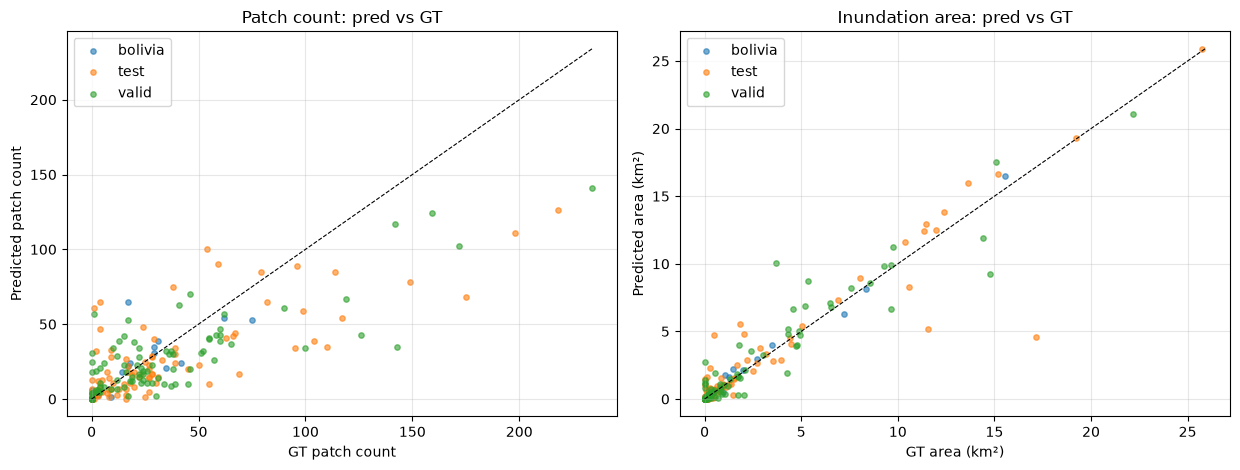

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
for s, g in df.groupby('split'):
    axes[0].scatter(g.n_gt, g.n_pred, s=15, alpha=0.6, label=s)
    axes[1].scatter(g.area_gt_km2, g.area_pred_km2, s=15, alpha=0.6, label=s)
lim = [0, df[['n_gt', 'n_pred']].max().max()]
axes[0].plot(lim, lim, 'k--', lw=0.8)
axes[0].set_xlabel('GT patch count'); axes[0].set_ylabel('Predicted patch count')
axes[0].set_title('Patch count: pred vs GT')
lim = [0, df[['area_gt_km2', 'area_pred_km2']].max().max()]
axes[1].plot(lim, lim, 'k--', lw=0.8)
axes[1].set_xlabel('GT area (km²)'); axes[1].set_ylabel('Predicted area (km²)')
axes[1].set_title('Inundation area: pred vs GT')
for ax in axes:
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

散点贴近对角线=准；点的横向/纵向偏离给出误差方向。可以看到：**面积散点明显比计数散点更贴对角线**（面积是连续量、容错高；计数对破碎小水体极敏感）。

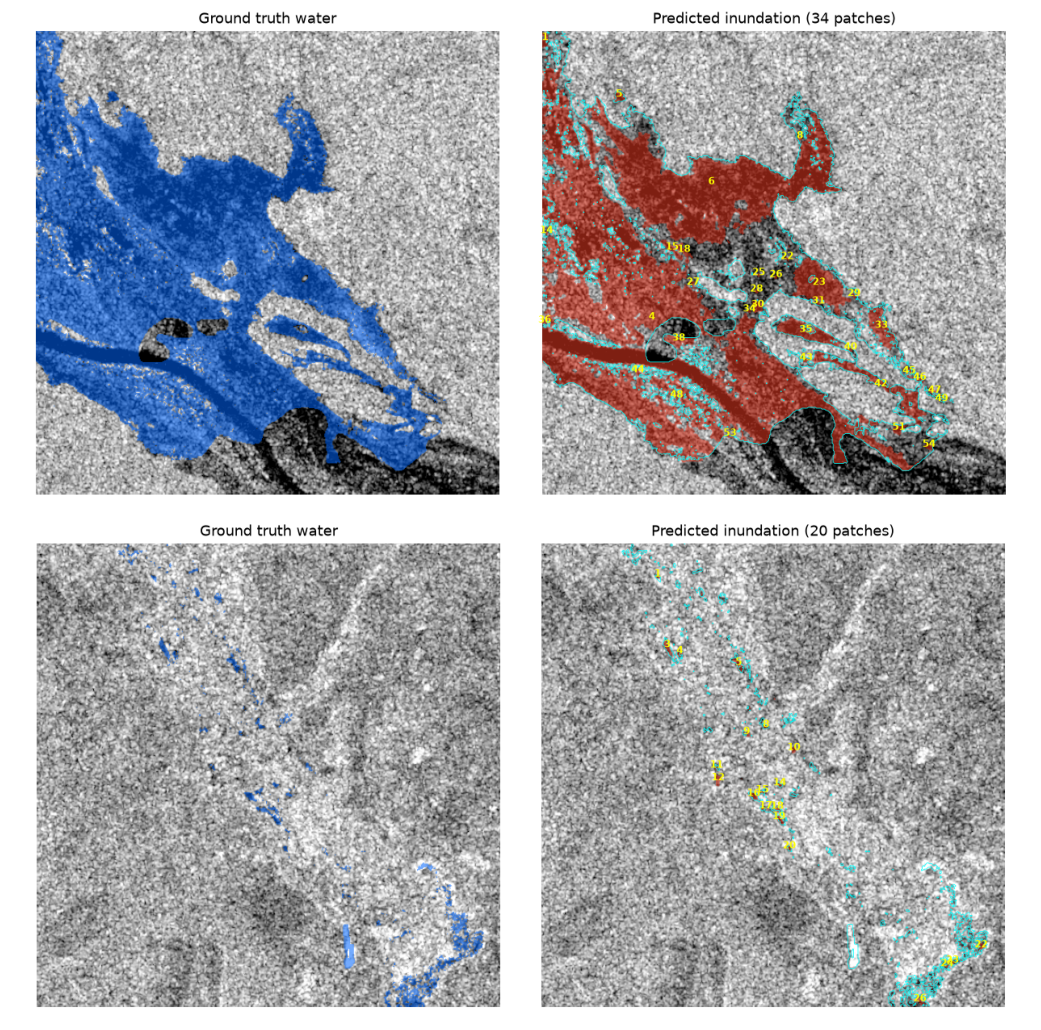

In [3]:
import matplotlib.image as mpimg

figs = sorted((OUT / 'figures/counting').glob('*_count.png'))[:2]
fig, axes = plt.subplots(len(figs), 1, figsize=(11.5, 5.2 * len(figs)))
for ax, p in zip(axes, figs):
    ax.imshow(mpimg.imread(p)); ax.axis('off')
plt.tight_layout(); plt.show()

## 三层精度结论（报告第 6 项的核心）

| 层级 | 精度 | 归因 |
| --- | --- | --- |
| **全域淹没总量** | 偏差仅 **+3.0%~+5.7%** | 面积是连续量，正负误差相互抵消 → 灾情快速评估**可用** |
| 逐图面积 | 中位误差 23~28% | 边缘漏检/误检贡献，与 IoU 0.66 一致 |
| 逐图斑块计数 | 中位误差 29~48%，分布内偏少 ~8 块 | 预测粘连合并小水体；13 张真值无水图有假阳性斑块；min_area 超参敏感 |

**业务解读**：如果水利部门的问的是"这次洪水淹了多少平方公里"，这套流程（三代中最稳的 UNet）已经能给出误差 <6% 的答案；如果要"有多少个独立淹没斑块"，需进一步做形态学分裂与噪声下限标定。